## Quantities
The exported data, that is used in this analysis, is already aggregated in the three requested quantities (for n from 1 to 250):
- total score : $ S_n = \sum^n_{i=1} X_i $;
- average score : $ \mu_n = S_n / n $;
- normalized total score : $ NS_n = S_n / \sqrt{n} $.

## Data storage
The data is stored in a json file.

*hw4_data.json*:
for each of the three model configurations are reported the quantities for all the m, n combinations. There are a total of 13500 triples of calculated quantities.

The json schema is composed of three objects (the model configurations), each containing three lists (for the m values in ascending order of m), each containing 1500 lists of three elements (for n values).

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

model_configuration_index = ['0', '1', '2']
model_configuration_name = ['Bernoulli p=0.2', 'Bernoulli p=0.75', 'Rademacher']
m = [3, 5, 14]
n = 1500

with open('hw4_data.json', 'r') as file:
    raw_data = json.load(file)

data: pd.DataFrame = pd.DataFrame(columns=['model_configuration', 'm', 'n', 'total', 'average', 'normalized'])

for mc in range(0, len(model_configuration_index)):
    for _m in range(0, len(m)):
        temp = pd.DataFrame.from_records(raw_data[model_configuration_index[mc]][_m], columns=['total', 'average', 'normalized'])
        temp['n'] = pd.Series([i for i in range(1, n+1)])
        temp['model_configuration'] = pd.Series([ model_configuration_name[mc] for i in range(1, n+1) ])
        temp['m'] = pd.Series([m[_m] for i in range(1, n+1)])

        data = pd.concat([data, temp])

print(f"Partial overview of data used in this analysis: {len(data)} rows.")
display(data)

Partial overview of data used in this analysis: 13500 rows.


,model_configuration,m,n,total,average,normalized
0,Bernoulli p=0.2,3,1,0,0.0,0.0
1,Bernoulli p=0.2,3,2,0,0.0,0.0
2,Bernoulli p=0.2,3,3,2,0.666667,1.154701
3,Bernoulli p=0.2,3,4,2,0.5,1.0
4,Bernoulli p=0.2,3,5,3,0.6,1.341641
...,...,...,...,...,...,...
1495,Rademacher,14,1496,16,0.010695,0.41367
1496,Rademacher,14,1497,14,0.009352,0.36184
1497,Rademacher,14,1498,12,0.008011,0.310045
1498,Rademacher,14,1499,16,0.010674,0.413256


## Trajectories' quantities plotting
The next figures represent the plotting of the data divided for the single quantities. For each of the visualizations its present a brief analysis before the plot.

In [82]:
import itertools as itt

col_labels = ['total', 'average', 'normalized']
col_names = ["Total score", 'Average score', 'Normalize total score']

def plot_column(col_i):
    fig, axs = plt.subplots(3, 3, figsize = (12, 8), sharex=True)
    for ax, [mc, _m] in zip(axs.flatten(), itt.product(model_configuration_name, m)):
        temp = data.query(f"(model_configuration == '{mc}') & (m == {_m})")
        ax.plot(temp.n, temp[col_labels[col_i]], linewidth=1)
        ax.set_title(f"{mc} model | m = {_m}")
        ax.set_xlabel("n")

    plt.suptitle(f"Plot for model configuration (rows) and m (cols)")
    plt.tight_layout()
    plt.show()

### Quantity: **total score**

For the total score plot we can notice the self-evident distinction between the Bernoulli and Rademacher model. The reason lies on the possible outcomes of the two models. While Bernoulli has only positive numbers, the Rademacher model has the positive and negative correspondent of 1. These specular options cause possible rapid trajectory changes, as clearly visible.

The two Bernoulli rows show the rapidness of climbing on the highest probability (p = 0.75), because the probability is associated with the point value 1. 

The effect of the various values of m is different between the models: Bernoulli indicates higher total score for large m, whereas Rademacher model highlights a difference only for the first two ms. The maximum total score reached by the highest value of m (14) and the middle value (5) seems the same, the minimum not. This phenomenon should be studied further: max total points reached for increasing m, how it varies? If it plateaus, maybe could be a "natural ceiling", or just the Law of Large Numbers in action?

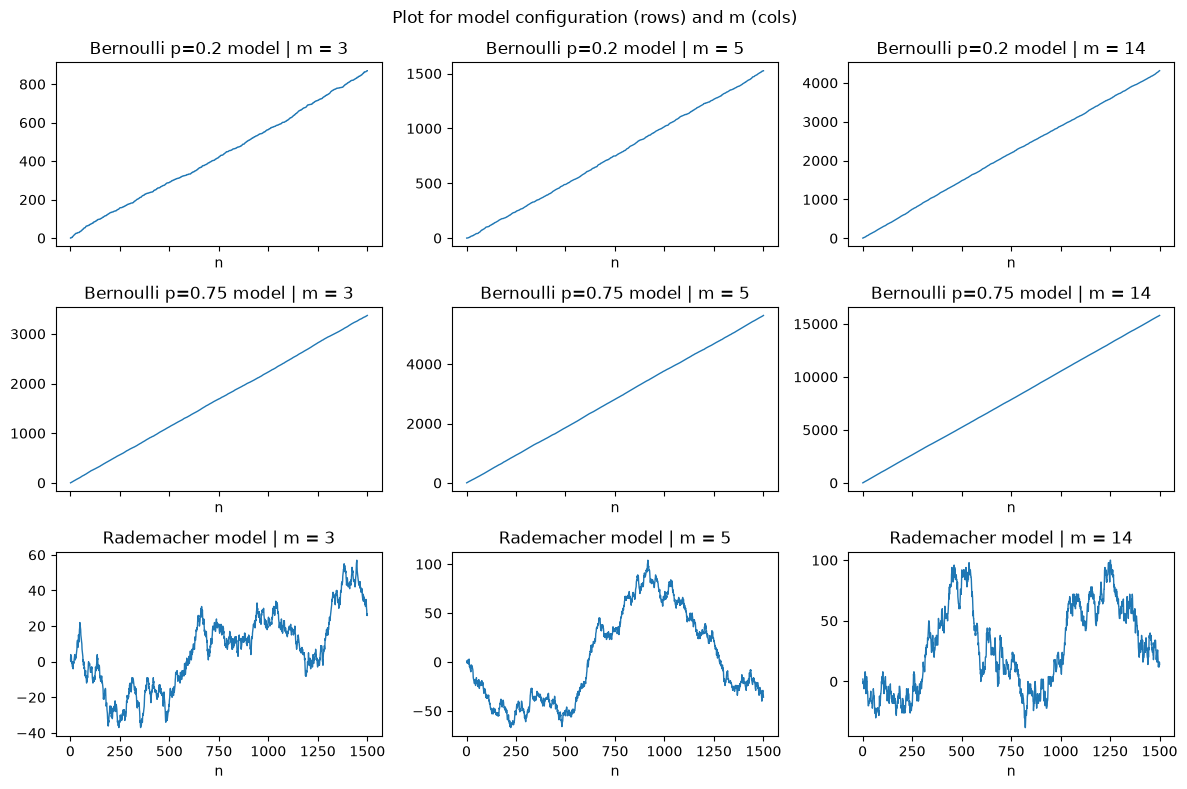

In [83]:
plot_column(0)

### Quantity: **average score**

Every plot shows a convergence of the average score for $n \rightarrow \infty$, this is due to the Law of Large Numbers. For the Rademacher model the convergence is at zero, because the equal probability of the opposite outcomes. On the other side, the Bernoulli model converges to the expected value $p * m$, because the method of aggregation used (description in the first section of this post).

Note that the increasing convergence is achieved through continuous oscillations.

This visualization (under the experiment assumptions) seems to point in a clear direction for securing a system: make the number of steps needed for a breach big enough. Is important to note that the cost in terms of time and money increases a lot for larger n. For this point, the results show similar effects compared to the almost perfect goal, even with a reasonable value of n.

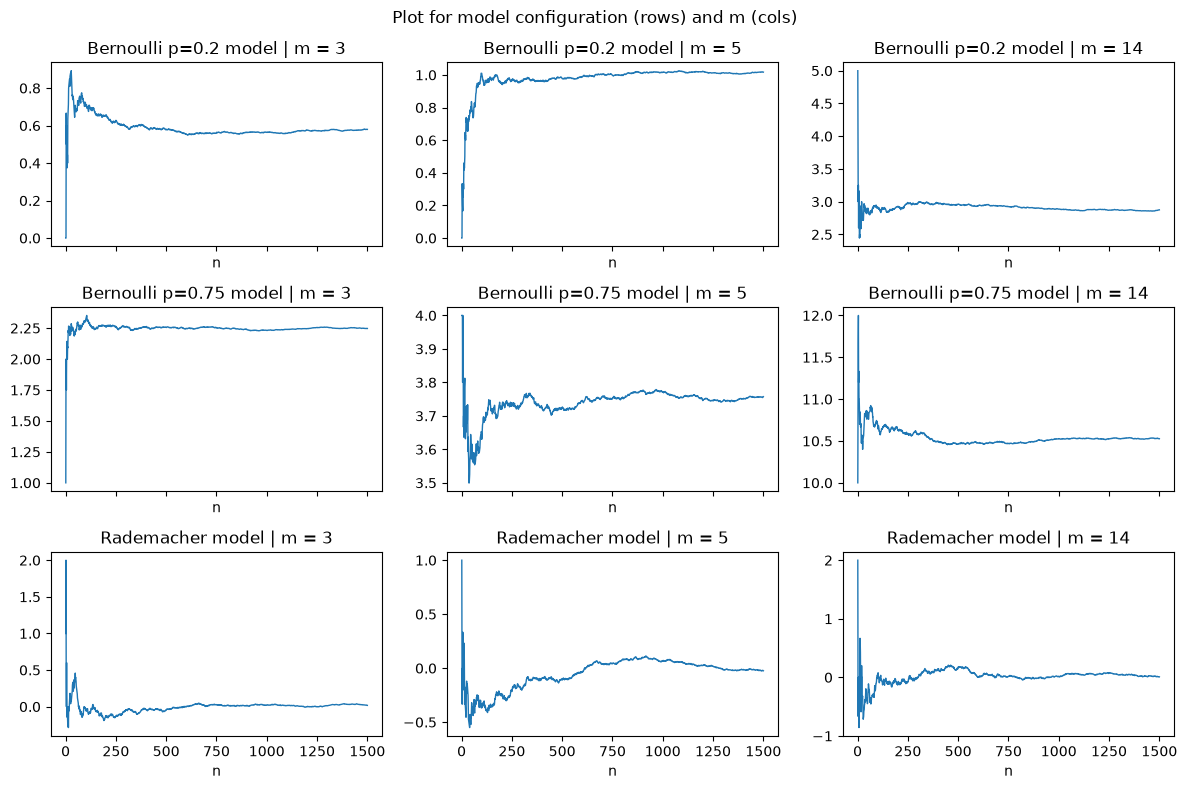

In [84]:
plot_column(1)

### Quantity: **normalized total score**

The normalized total score quantity does not show any particular aspect. From the homework assignment we might have expected a sort of convergence of Rademacher model's configurations into a normal distribution, as stated by the Central Limit Theorem, but it did not happen. The almost certain reason are the experiment's assumptions.

If you are asking yourself: does it happen with larger n? The answer is no, nothing changed when the attempt was made with ten times the value of n. The distribution continues to grow (in the long term) with oscillations (very similar to the ones displayed here).

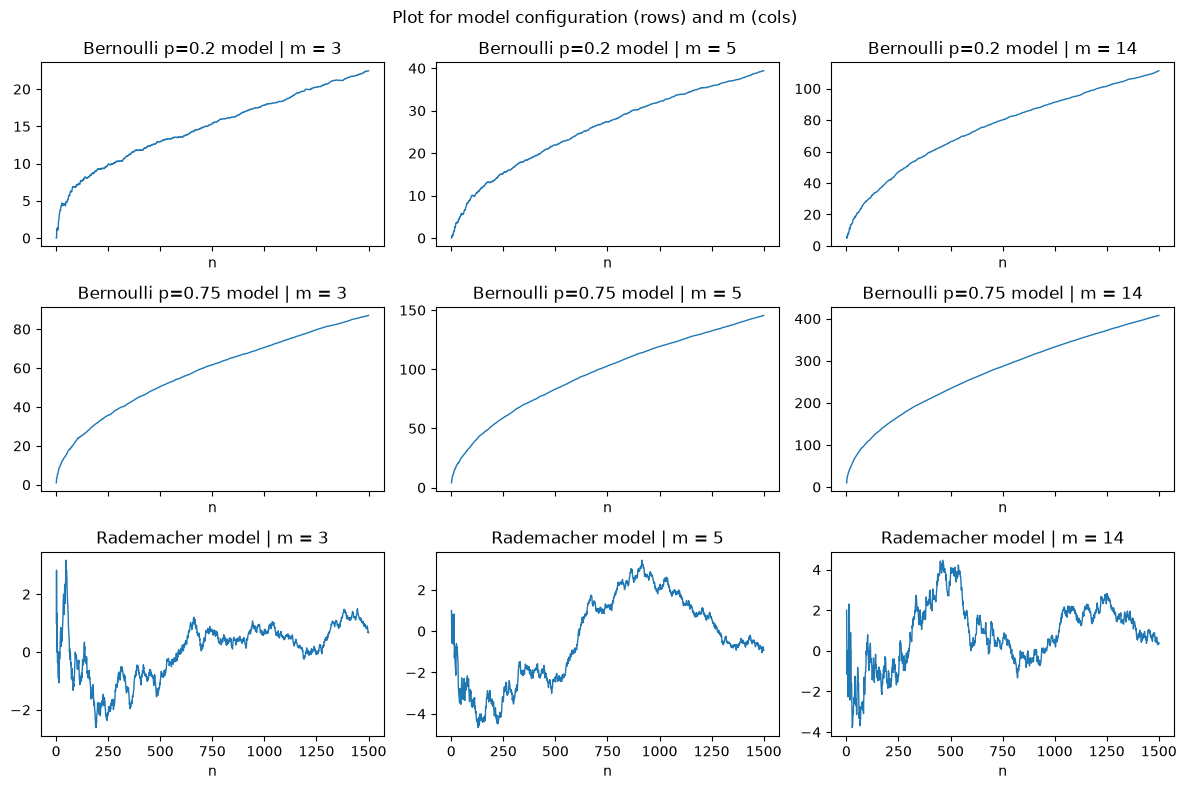

In [85]:
plot_column(2)